# Projet AML — Prédiction de la réadmission (XGBoost) + export pour le déploiement
**Jeu de données :** Diabetes 130-US Hospitals (1999-2008) — `diabetic_data.csv`

## Objectif métier
> **Aider l'hôpital à mieux prendre en charge les patients diabétiques, en repérant ceux qui risquent de revenir à l'hôpital peu après leur sortie.**

## Objectif Data Science
> **Construire un modèle de classification supervisée qui prédit, à partir des données cliniques du patient, sa catégorie de réadmission : `<30`, `>30` ou `NO`.**

Variable cible `readmitted` avec ses 3 modalités : `<30` (réadmis en moins de 30 jours), `>30` (réadmis plus tard), `NO` (jamais réadmis).

## Algorithme retenu : XGBoost
Dans l'étude comparative (Random Forest, AdaBoost, XGBoost), **XGBoost a obtenu les meilleurs résultats**. Ce notebook n'utilise donc que lui.
C'est une méthode de *boosting* (cours « Méthodes ensemblistes ») : de nombreux petits arbres de décision construits **en série**, chacun corrigeant les erreurs du précédent.

## Plan
| Partie | Contenu |
|---|---|
| 1. Préparation des données | Nettoyage, transformation, corrélation, ACP |
| 2. Modélisation | XGBoost réglé par RandomizedSearchCV |
| 3. Évaluation | Accuracy, matrice de confusion, ROC, importance des variables, seuil d'alerte `<30` |
| 4. Export pour le déploiement | `model.joblib` + `config.json` + test de rechargement + `artifacts.zip` |

In [3]:
import os, json, shutil, platform, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, auc, f1_score)
import xgboost as xgb

# 1. Préparation des données
## 1.1 Chargement
Dans ce fichier, `?` signifie « valeur manquante ». `keep_default_na=False` évite que `None` (« test non effectué » dans `A1Cresult` et `max_glu_serum`) soit lu comme un manquant.

**Sur Google Colab :** si le fichier n'est pas présent, la cellule suivante te demande de l'importer (`diabetic_data.csv`).

In [4]:
if not os.path.exists("diabetic_data.csv"):
    try:
        from google.colab import files
        print("Sélectionne le fichier diabetic_data.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Place diabetic_data.csv dans le même dossier que ce notebook.")

df = pd.read_csv("diabetic_data.csv", na_values="?", keep_default_na=False, low_memory=False)
print("Dimensions :", df.shape)
df.head()

Dimensions : (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1.2 Nettoyage
- **Doublons** supprimés.
- **Un seul séjour par patient** (`patient_nbr`) : sinon le même patient serait dans le train et dans le test.
- **Patients décédés** retirés (codes de sortie 11, 19, 20, 21 = « Expired » dans `IDS_mapping.csv`) : un patient décédé ne peut pas être réadmis.

In [5]:
print("Avant :", df.shape)
df = df.drop_duplicates()
df = df.drop_duplicates(subset="patient_nbr", keep="first")
df = df[~df["discharge_disposition_id"].isin([11, 19, 20, 21])]
df = df.reset_index(drop=True)
print("Après :", df.shape)

Avant : (101766, 50)
Après : (70434, 50)


### Variable cible (3 classes)
On garde `readmitted` avec ses 3 modalités. `LabelEncoder` les transforme en nombres : **`<30` → 0, `>30` → 1, `NO` → 2**.

In [6]:
statut = df["readmitted"].copy()

le_cible = LabelEncoder()
y = pd.Series(le_cible.fit_transform(statut), name="readmitted")
noms_classes = list(le_cible.classes_)

df = df.drop(columns="readmitted")      # la réponse ne doit pas rester dans les variables explicatives

print("Codage :", dict(zip(noms_classes, le_cible.transform(noms_classes).tolist())))
print((statut.value_counts(normalize=True) * 100).round(1).rename("% des patients"))

Codage : {'<30': 0, '>30': 1, 'NO': 2}
readmitted
NO     59.5
>30    31.6
<30     8.9
Name: % des patients, dtype: float64


**À retenir :** `NO` est la classe majoritaire (≈ 59 %). Un modèle « bête » qui répondrait toujours `NO` aurait donc déjà ≈ 59 % d'accuracy : c'est la **ligne de base** à battre.

### Valeurs manquantes et colonnes inutiles
- Colonnes à plus de 50 % de manquants → supprimées (`weight`).
- Identifiants (`encounter_id`, `patient_nbr`) et colonnes constantes → supprimés.
- Diagnostics `diag_1/2/3` (des centaines de codes ICD-9) → regroupés en grandes familles de maladies.
- Manquants restants → modalité « Inconnu ».

In [7]:
pct_manquants = df.isnull().mean() * 100
cols_trop_vides = pct_manquants[pct_manquants > 50].index.tolist()
cols_id = ["encounter_id", "patient_nbr"]
cols_constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Supprimées :", cols_trop_vides + cols_id + cols_constantes)
df = df.drop(columns=cols_trop_vides + cols_id + cols_constantes)

def groupe_diagnostic(code):
    if pd.isnull(code):
        return "Inconnu"
    code = str(code)
    if code.startswith(("V", "E")):
        return "Autre"
    n = float(code)
    if 390 <= n <= 459 or n == 785: return "Circulatoire"
    if 460 <= n <= 519 or n == 786: return "Respiratoire"
    if 520 <= n <= 579 or n == 787: return "Digestif"
    if int(n) == 250:               return "Diabete"
    if 800 <= n <= 999:             return "Blessure"
    if 710 <= n <= 739:             return "Musculo-squelettique"
    if 580 <= n <= 629 or n == 788: return "Genito-urinaire"
    if 140 <= n <= 239:             return "Tumeurs"
    return "Autre"

for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].apply(groupe_diagnostic)

df = df.fillna("Inconnu")
print("Manquants restants :", df.isnull().sum().sum(), "| Taille :", df.shape)

Supprimées : ['weight', 'encounter_id', 'patient_nbr', 'examide', 'citoglipton', 'glimepiride-pioglitazone']
Manquants restants : 0 | Taille : (70434, 43)


## 1.3 Transformation
- **Encodage** (`LabelEncoder`, comme au TP) : chaque texte devient un nombre. On **garde les encodeurs** : ils serviront au déploiement pour traduire la saisie d'un nouveau patient.
- **Normalisation** (`StandardScaler`) : sert à la corrélation et à l'ACP (XGBoost n'en a pas besoin).

In [8]:
df_raw = df.copy()                       # version lisible (avant encodage) : sert au déploiement
df_encoded = df.copy()

label_encoders = {}
for col in df_encoded.select_dtypes(exclude="number").columns:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le

X = df_encoded.copy()
X_normalized = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
print("X :", X.shape, "| y :", y.shape)

X : (70434, 43) | y : (70434,)


## 1.4 Corrélation avec la cible
La cible a 3 classes : on calcule la corrélation avec chaque modalité (une colonne 0/1 par modalité, pour l'exploration seulement).

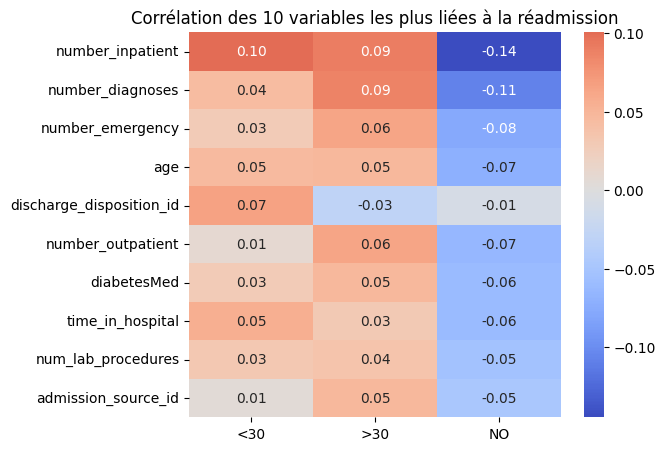

In [9]:
indicateurs = pd.get_dummies(statut).astype(int)
corr_modalites = pd.DataFrame({m: X_normalized.corrwith(indicateurs[m]) for m in indicateurs.columns})
top10 = corr_modalites.abs().max(axis=1).sort_values(ascending=False).head(10).index

plt.figure(figsize=(6, 5))
sns.heatmap(corr_modalites.loc[top10], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation des 10 variables les plus liées à la réadmission")
plt.show()

**Lecture :** toutes les corrélations sont **faibles** (≈ 0,15 au maximum). `number_inpatient` (hospitalisations passées) est la plus liée : plus un patient a été hospitalisé récemment, plus il a de chances de revenir.
On garde toutes les variables : XGBoost saura trouver les relations non linéaires.

## 1.5 ACP (Analyse en Composantes Principales)
L'ACP résume des variables corrélées en quelques axes qui gardent un maximum de variance. On l'applique aux **8 variables numériques réelles** (durées et compteurs).

In [10]:
vars_acp = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

pca = PCA()
pca_components = pca.fit_transform(StandardScaler().fit_transform(df_raw[vars_acp]))

eig = pd.DataFrame({
    "Dimension": ["Dim" + str(i + 1) for i in range(len(pca.explained_variance_))],
    "Valeur propre": np.round(pca.explained_variance_, 2),
    "% variance": np.round(pca.explained_variance_ratio_ * 100, 2),
    "% cumulé": np.round(np.cumsum(pca.explained_variance_ratio_) * 100, 2)
})
n_kaiser = int((pca.explained_variance_ > 1).sum())
print("Composantes retenues (Kaiser, valeur propre > 1) :", n_kaiser,
      "| variance conservée : {:.1f} %".format(pca.explained_variance_ratio_[:n_kaiser].sum() * 100))
eig

Composantes retenues (Kaiser, valeur propre > 1) : 3 | variance conservée : 53.8 %


,Dimension,Valeur propre,% variance,% cumulé
0,Dim1,2.04,25.49,25.49
1,Dim2,1.25,15.64,41.12
2,Dim3,1.01,12.63,53.75
3,Dim4,0.94,11.69,65.44
4,Dim5,0.84,10.55,75.99
5,Dim6,0.82,10.27,86.26
6,Dim7,0.64,7.95,94.21
7,Dim8,0.46,5.79,100.00


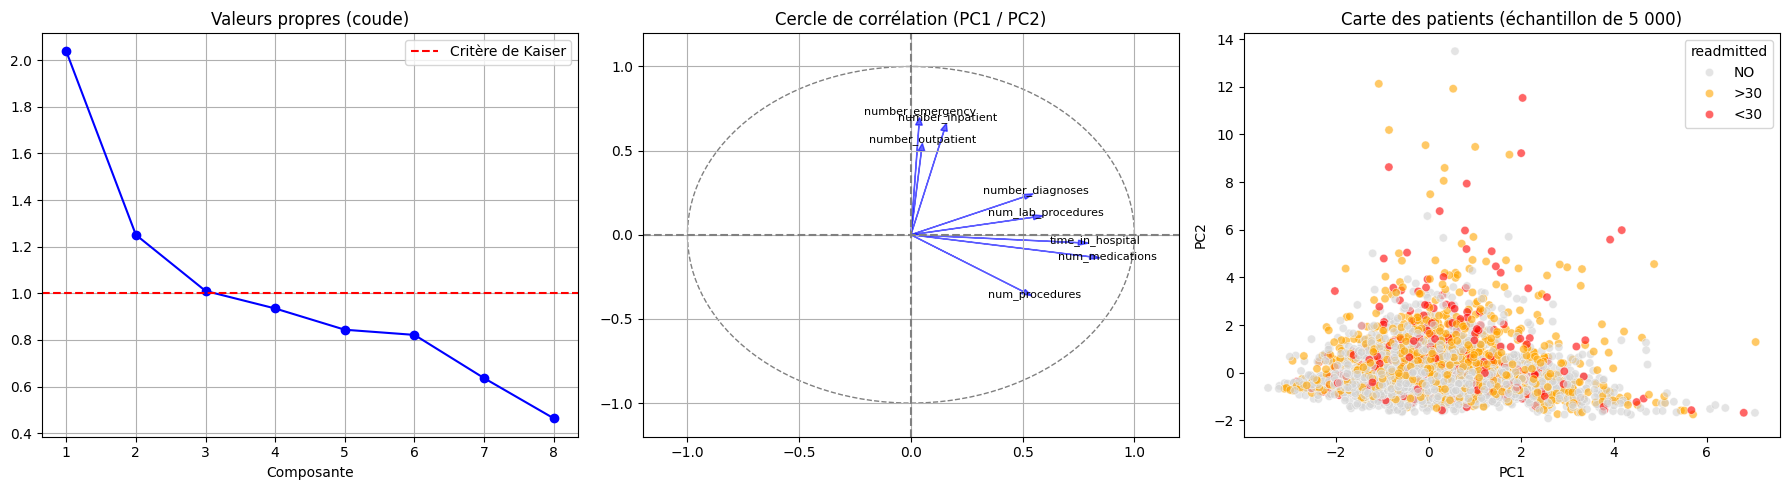

In [11]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Coude + Kaiser
axes[0].plot(range(1, len(pca.explained_variance_) + 1), pca.explained_variance_, marker="o", color="b")
axes[0].axhline(1, color="r", linestyle="--", label="Critère de Kaiser")
axes[0].set_title("Valeurs propres (coude)"); axes[0].set_xlabel("Composante"); axes[0].legend(); axes[0].grid(True)

# Cercle de corrélation
axes[1].axhline(0, color="grey", linestyle="--"); axes[1].axvline(0, color="grey", linestyle="--")
for i, var in enumerate(vars_acp):
    axes[1].arrow(0, 0, loadings[i, 0], loadings[i, 1], color="b", alpha=0.6, head_width=0.03)
    axes[1].text(loadings[i, 0] * 1.1, loadings[i, 1] * 1.1, var, fontsize=8, ha="center")
axes[1].add_artist(plt.Circle((0, 0), 1, color="gray", fill=False, linestyle="--"))
axes[1].set_xlim(-1.2, 1.2); axes[1].set_ylim(-1.2, 1.2)
axes[1].set_title("Cercle de corrélation (PC1 / PC2)"); axes[1].grid(True)

# Carte des individus
pca_df = pd.DataFrame(pca_components[:, :2], columns=["PC1", "PC2"])
pca_df["readmitted"] = statut.values
ech = pca_df.sample(5000, random_state=42)
sns.scatterplot(data=ech, x="PC1", y="PC2", hue="readmitted", hue_order=["NO", ">30", "<30"],
                palette={"NO": "lightgrey", ">30": "orange", "<30": "red"}, alpha=0.6, ax=axes[2])
axes[2].set_title("Carte des patients (échantillon de 5 000)")
plt.tight_layout()
plt.show()

**Lecture de l'ACP :**
- Kaiser retient **3 composantes** (≈ 54 % de l'information).
- **PC1 = « intensité du séjour »** (durée, médicaments, analyses, procédures, diagnostics) ; **PC2 = « antécédents de visites »** (urgences, hospitalisations, consultations).
- Les 3 classes sont **très mélangées** sur la carte : aucun axe ne les sépare nettement. Le problème est difficile, d'où le choix d'un modèle plus puissant : XGBoost.

---
# 2. Modélisation : XGBoost
## 2.1 Séparation entraînement / test
80 % des patients pour apprendre, 20 % pour tester sur des patients jamais vus. `stratify=y` garde la même proportion des 3 classes dans les deux parties.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Entraînement :", X_train.shape, "| Test :", X_test.shape)

classe_majoritaire = pd.Series(y_train).value_counts().idxmax()
accuracy_base = (y_test == classe_majoritaire).mean()
print("Ligne de base (toujours {}) : accuracy = {:.3f}".format(noms_classes[classe_majoritaire], accuracy_base))

Entraînement : (56347, 43) | Test : (14087, 43)
Ligne de base (toujours NO) : accuracy = 0.595


## 2.2 Réglage des hyperparamètres (RandomizedSearchCV)
Comme dans le TP, on teste **15 combinaisons** tirées au hasard, évaluées par validation croisée (`cv=3`), en optimisant l'**accuracy**.
Hyperparamètres principaux : `learning_rate` (vitesse d'apprentissage), `max_depth` (profondeur des arbres), `n_estimators` (nombre d'arbres), `subsample` / `colsample_bytree` (part des patients / variables utilisée par arbre), `min_child_weight`, `gamma`, `reg_alpha`, `reg_lambda` (régularisation : limitent le surapprentissage).
`objective="multi:softprob"` fait calculer une probabilité pour chacune des 3 classes.

In [13]:
param_grid = {
    "learning_rate": [0.2, 0.1, 0.05, 0.03, 0.01],
    "max_depth": [2, 3, 4, 5, 6, 7],
    "n_estimators": [100, 200, 300, 500],
    "subsample": [0.6, 0.7, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 10],
    "gamma": [0, 0.5, 1, 2],
    "reg_alpha": [0, 1, 10],
    "reg_lambda": [1, 5, 10]
}

random_search = RandomizedSearchCV(
    xgb.XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", random_state=42),
    param_distributions=param_grid,
    n_iter=15,
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)

print("Meilleurs paramètres :", random_search.best_params_)
print("Meilleure accuracy (validation croisée) : {:.3f}".format(random_search.best_score_))

best_model = random_search.best_estimator_

Meilleurs paramètres : {'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 1, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.2, 'gamma': 0.5, 'colsample_bytree': 0.6}
Meilleure accuracy (validation croisée) : 0.616


---
# 3. Évaluation
On évalue sur le **jeu de test** (patients jamais vus).

## 3.1 Accuracy, F1 macro et AUC
- **Accuracy** : part de patients bien classés (parmi les 3 classes), à comparer à la ligne de base (≈ 59 %, toujours `NO`).
- **F1 macro** : moyenne du F1 des 3 classes (donne le même poids à la petite classe `<30`).
- **AUC (un contre tous)** : capacité à distinguer chaque classe des deux autres (0,5 = hasard).

In [14]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)

acc = accuracy_score(y_test, y_pred)
f1m = f1_score(y_test, y_pred, average="macro")
auc_ovr = roc_auc_score(y_test, y_proba, multi_class="ovr")

print("Accuracy du modèle XGBoost          : {:.3f}".format(acc))
print("Accuracy de la ligne de base (NO)   : {:.3f}".format(accuracy_base))
print("Gain par rapport à la ligne de base : {:+.3f}".format(acc - accuracy_base))
print("F1 macro                            : {:.3f}".format(f1m))
print("AUC (un contre tous, moyenne)       : {:.3f}".format(auc_ovr))

Accuracy du modèle XGBoost          : 0.616
Accuracy de la ligne de base (NO)   : 0.595
Gain par rapport à la ligne de base : +0.021
F1 macro                            : 0.366
AUC (un contre tous, moyenne)       : 0.657


## 3.2 Matrice de confusion et rapport par classe
Chaque ligne = vraie classe, chaque colonne = classe prédite. La diagonale = patients bien classés.

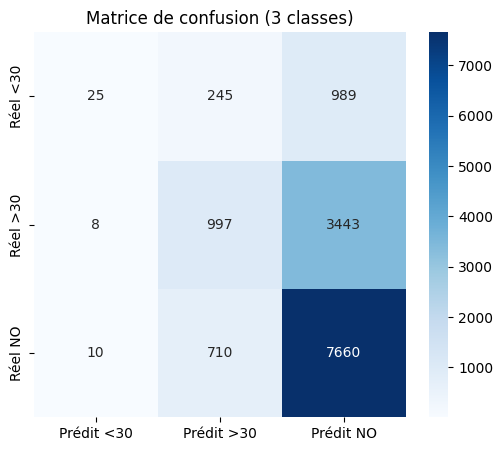

              precision    recall  f1-score   support

         <30       0.58      0.02      0.04      1259
         >30       0.51      0.22      0.31      4448
          NO       0.63      0.91      0.75      8380

    accuracy                           0.62     14087
   macro avg       0.58      0.39      0.37     14087
weighted avg       0.59      0.62      0.55     14087



In [15]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prédit " + n for n in noms_classes],
            yticklabels=["Réel " + n for n in noms_classes])
plt.title("Matrice de confusion (3 classes)")
plt.show()

print(classification_report(y_test, y_pred, target_names=noms_classes, zero_division=0))

**Lecture :** `NO` (classe la plus grosse) est bien détectée, `>30` moyennement, et `<30` (la plus rare, et la plus importante pour l'hôpital) **très peu** quand on décide par la classe la plus probable.
Le modèle reste utile pour `<30` à condition d'utiliser sa **probabilité** plutôt que sa seule classe prédite : c'est l'objet du seuil d'alerte (3.5).

## 3.3 Courbes ROC (un contre tous)

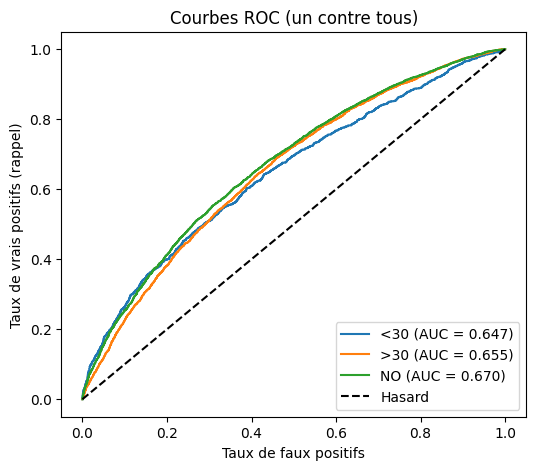

In [16]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
plt.figure(figsize=(6, 5))
for i, nom in enumerate(noms_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, label="{} (AUC = {:.3f})".format(nom, auc(fpr, tpr)))
plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs (rappel)")
plt.title("Courbes ROC (un contre tous)")
plt.legend(loc="lower right")
plt.show()

## 3.4 Importance des variables

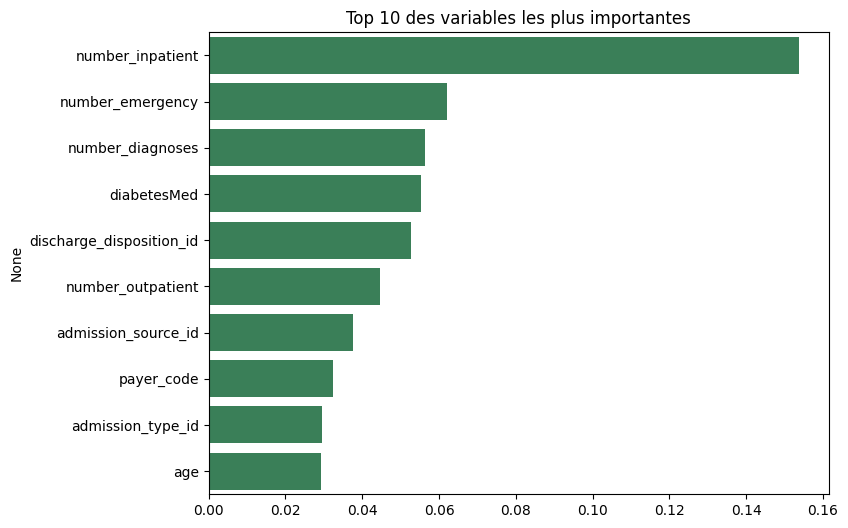

,0
number_inpatient,0.154
number_emergency,0.062
number_diagnoses,0.056
diabetesMed,0.055
discharge_disposition_id,0.053
number_outpatient,0.045
admission_source_id,0.038
payer_code,0.033
admission_type_id,0.030
age,0.029


In [17]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(x=importances.head(10).values, y=importances.head(10).index, color="seagreen")
plt.title("Top 10 des variables les plus importantes")
plt.show()
importances.head(10).round(3)

## 3.5 Seuil d'alerte pour les patients à risque de retour rapide (`<30`)
Pour répondre à l'objectif métier, on utilise la **probabilité d'être `<30`** donnée par le modèle.
On déclenche une **alerte** pour les patients dont cette probabilité est dans les 20 % les plus élevés du jeu de test, puis on mesure ce que cette alerte permet de détecter.
Ce seuil sera enregistré dans la configuration pour le déploiement.

In [18]:
p30 = y_proba[:, 0]                                 # probabilité d'être réadmis en moins de 30 jours
seuil_alerte = float(np.quantile(p30, 0.80))        # 20 % des patients ont une probabilité plus élevée
alerte = p30 >= seuil_alerte
vrai_30 = (y_test.values == 0)

taux_base = vrai_30.mean()
precision_alerte = vrai_30[alerte].mean()
rappel_alerte = alerte[vrai_30].mean()

print("Seuil d'alerte (probabilité <30) : {:.3f}".format(seuil_alerte))
print("Patients en alerte               : {:.0f} % du test".format(alerte.mean() * 100))
print("Taux de <30 dans la population   : {:.1f} %".format(taux_base * 100))
print("Taux de <30 parmi les alertes    : {:.1f} %  (x{:.1f} par rapport à la population)".format(precision_alerte * 100, precision_alerte / taux_base))
print("Part des <30 captés par l'alerte : {:.1f} %".format(rappel_alerte * 100))

Seuil d'alerte (probabilité <30) : 0.117
Patients en alerte               : 20 % du test
Taux de <30 dans la population   : 8.9 %
Taux de <30 parmi les alertes    : 17.0 %  (x1.9 par rapport à la population)
Part des <30 captés par l'alerte : 38.0 %


**Lecture :** en suivant de près seulement 20 % des patients (ceux dont le score est le plus élevé), on repère une part nettement plus grande de futurs `<30` que par tirage au hasard.
Le modèle sert donc à **prioriser** le suivi, pas à décider seul.

---
# 4. Export pour le déploiement
On sauvegarde dans un dossier `artifacts/` :
- **`model.joblib`** : le modèle XGBoost entraîné ;
- **`config.json`** : tout ce dont l'application a besoin pour préparer la saisie d'un nouveau patient (ordre des colonnes, encodage, valeurs par défaut, champs du formulaire, classes, seuil d'alerte, versions des bibliothèques).

## 4.1 Champs du formulaire
Le formulaire ne demande qu'un nombre limité d'informations ; **toutes les autres sont remplacées par une valeur typique** (médiane pour les nombres, valeur la plus fréquente pour les catégories), comme pour le module de segmentation.

In [19]:
# (nom de la colonne, libellé affiché, type)
CHAMPS = [
    ("age",               "Tranche d'âge",                              "choix"),
    ("gender",            "Sexe",                                       "choix"),
    ("time_in_hospital",  "Durée du séjour (jours)",                    "nombre"),
    ("num_lab_procedures","Nombre d'analyses de laboratoire",           "nombre"),
    ("num_procedures",    "Nombre de procédures (hors laboratoire)",    "nombre"),
    ("num_medications",   "Nombre de médicaments administrés",          "nombre"),
    ("number_diagnoses",  "Nombre de diagnostics",                      "nombre"),
    ("number_outpatient", "Consultations externes (année précédente)",  "nombre"),
    ("number_emergency",  "Passages aux urgences (année précédente)",   "nombre"),
    ("number_inpatient",  "Hospitalisations (année précédente)",        "nombre"),
    ("diag_1",            "Diagnostic principal (famille de maladies)", "choix"),
    ("A1Cresult",         "Résultat HbA1c",                             "choix"),
    ("insulin",           "Insuline",                                   "choix"),
    ("change",            "Traitement modifié pendant le séjour ?",     "choix"),
    ("diabetesMed",       "Antidiabétiques prescrits ?",                "choix"),
]

# libellés lisibles pour certaines modalités
LIBELLES = {
    "gender":      {"Female": "Femme", "Male": "Homme"},
    "A1Cresult":   {"None": "Non mesuré", "Norm": "Normal", ">7": "> 7", ">8": "> 8"},
    "insulin":     {"No": "Non prescrit", "Steady": "Dose stable", "Up": "Dose augmentée", "Down": "Dose diminuée"},
    "change":      {"No": "Non", "Ch": "Oui"},
    "diabetesMed": {"No": "Non", "Yes": "Oui"},
}

# colonnes numériques "compteurs" (on limite les valeurs extrêmes) et colonnes numériques "codes" (on garde le code)
cols_num = df_raw.select_dtypes(include="number").columns.tolist()
cols_codes = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
cols_compteurs = [c for c in cols_num if c not in cols_codes]
cols_cat = list(label_encoders.keys())

print("Colonnes du modèle :", X.shape[1])
print("Compteurs :", cols_compteurs)
print("Codes     :", cols_codes)
print("Catégories:", len(cols_cat), "colonnes")

Colonnes du modèle : 43
Compteurs : ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Codes     : ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
Catégories: 32 colonnes


## 4.2 Construction de la configuration

In [20]:
def en_python(v):
    # convertit les types numpy en types Python (nécessaire pour écrire du JSON)
    if isinstance(v, (np.integer,)):  return int(v)
    if isinstance(v, (np.floating,)): return float(v)
    return v

# valeurs typiques pour les informations non demandées
defaults = {}
for col in X.columns:
    if col in cols_compteurs:
        defaults[col] = en_python(df_raw[col].median())
    else:
        defaults[col] = en_python(df_raw[col].mode()[0])

# bornes pour les compteurs (1er et 99e centile) : évite les saisies aberrantes
caps = {col: [float(df_raw[col].quantile(0.01)), float(df_raw[col].quantile(0.99))] for col in cols_compteurs}

# encodage : la position d'une modalité dans la liste = son code numérique
categories = {col: [str(c) for c in label_encoders[col].classes_] for col in cols_cat}

# description des champs du formulaire
champs_formulaire = []
for nom, libelle, type_champ in CHAMPS:
    champ = {"name": nom, "label": libelle, "type": type_champ, "default": defaults[nom]}
    if type_champ == "nombre":
        champ["min"] = int(np.floor(caps[nom][0]))
        champ["max"] = int(np.ceil(caps[nom][1]))
    else:
        freq = df_raw[nom].astype(str).value_counts(normalize=True)
        valeurs = [v for v in categories[nom] if freq.get(v, 0) >= 0.001]       # on écarte les modalités quasi inexistantes
        champ["choices"] = [{"value": v, "label": LIBELLES.get(nom, {}).get(v, v)} for v in valeurs]
    champs_formulaire.append(champ)

# description des 3 classes (hypothèses à valider par des cliniciens)
classes = {
    "0": {"name": "<30", "label": "Réadmission en moins de 30 jours",
          "action": "Suivi renforcé avant la sortie : rendez-vous de contrôle rapide, revue du traitement, appel de suivi."},
    "1": {"name": ">30", "label": "Réadmission après 30 jours",
          "action": "Suivi à moyen terme et éducation thérapeutique."},
    "2": {"name": "NO", "label": "Pas de réadmission",
          "action": "Parcours standard, éducation thérapeutique de base."}
}
assert [classes[str(i)]["name"] for i in range(3)] == noms_classes      # sécurité : même ordre que l'encodage de la cible

config = {
    "columns": X.columns.tolist(),          # ordre exact des colonnes du modèle
    "num_cols": cols_compteurs,
    "code_cols": cols_codes,
    "cat_cols": cols_cat,
    "categories": categories,
    "caps": caps,
    "defaults": defaults,
    "form_fields": champs_formulaire,
    "classes": classes,
    "alert": {
        "class_index": 0,
        "threshold": seuil_alerte,
        "description": "Alerte si la probabilité de réadmission < 30 jours dépasse ce seuil (20 % des patients les plus à risque du jeu de test).",
        "share_alerted_pct": round(float(alerte.mean() * 100), 1),
        "precision_pct": round(float(precision_alerte * 100), 1),
        "recall_pct": round(float(rappel_alerte * 100), 1),
        "base_rate_pct": round(float(taux_base * 100), 1)
    },
    "metrics": {
        "accuracy": round(float(acc), 3),
        "baseline_accuracy": round(float(accuracy_base), 3),
        "f1_macro": round(float(f1m), 3),
        "auc_ovr": round(float(auc_ovr), 3)
    },
    "versions": {
        "sklearn": sklearn.__version__,
        "xgboost": xgb.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "python": platform.python_version()
    }
}
print("Configuration construite :", len(config["form_fields"]), "champs de formulaire,", len(config["columns"]), "colonnes du modèle")

Configuration construite : 15 champs de formulaire, 43 colonnes du modèle


## 4.3 Sauvegarde des fichiers

In [21]:
OUT = "artifacts"
os.makedirs(OUT, exist_ok=True)

joblib.dump({"model": best_model}, os.path.join(OUT, "model.joblib"))
with open(os.path.join(OUT, "config.json"), "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Fichiers exportés :", sorted(os.listdir(OUT)))
print()
print("Versions utilisées (à installer à l'identique sur le PC) :")
for nom_lib, version in config["versions"].items():
    print("  {:8s} {}".format(nom_lib, version))

Fichiers exportés : ['config.json', 'model.joblib']

Versions utilisées (à installer à l'identique sur le PC) :
  sklearn  1.6.1
  xgboost  3.4.1
  pandas   2.2.3
  numpy    2.4.6
  python   3.13.18


## 4.4 Test de rechargement et prédiction pour un nouveau patient
On recharge les fichiers **comme le ferait l'application**, puis on prédit pour deux patients saisis à la main.
La fonction `predire_patient` montre exactement la préparation à faire côté application : valeurs par défaut, limitation des extrêmes, encodage dans l'ordre des colonnes, puis prédiction.

In [22]:
modele = joblib.load(os.path.join(OUT, "model.joblib"))["model"]
cfg = json.load(open(os.path.join(OUT, "config.json"), encoding="utf-8"))

def predire_patient(saisie):
    # 1) valeurs typiques pour tout ce qui n'est pas saisi
    ligne = dict(cfg["defaults"])
    ligne.update(saisie)

    # 2) compteurs : on limite aux bornes
    for col in cfg["num_cols"]:
        bas, haut = cfg["caps"][col]
        ligne[col] = min(max(float(ligne[col]), bas), haut)

    # 3) catégories : texte -> code (une modalité inconnue est remplacée par la valeur typique)
    for col in cfg["cat_cols"]:
        modalites = cfg["categories"][col]
        valeur = str(ligne[col])
        if valeur not in modalites:
            valeur = str(cfg["defaults"][col])
        ligne[col] = modalites.index(valeur)

    # 4) DataFrame dans l'ordre exact des colonnes du modèle
    X_new = pd.DataFrame([[ligne[c] for c in cfg["columns"]]], columns=cfg["columns"])

    # 5) prédiction
    proba = modele.predict_proba(X_new)[0]
    idx = int(np.argmax(proba))
    p30 = float(proba[cfg["alert"]["class_index"]])
    return {
        "classe": cfg["classes"][str(idx)]["name"],
        "probabilites": {cfg["classes"][str(i)]["name"]: round(float(p), 3) for i, p in enumerate(proba)},
        "alerte_30j": p30 >= cfg["alert"]["threshold"],
        "action": cfg["classes"][str(idx)]["action"]
    }

# Patient 1 : séjour court, aucun antécédent
patient_simple = {"age": "[60-70)", "time_in_hospital": 2, "number_inpatient": 0, "number_emergency": 0,
                  "number_outpatient": 0, "num_medications": 8, "number_diagnoses": 5}

# Patient 2 : séjour long, plusieurs hospitalisations et urgences l'année précédente
patient_risque = {"age": "[70-80)", "time_in_hospital": 9, "number_inpatient": 4, "number_emergency": 2,
                  "number_outpatient": 1, "num_medications": 22, "number_diagnoses": 9, "diabetesMed": "Yes", "insulin": "Up"}

for nom_patient, saisie in [("Patient simple", patient_simple), ("Patient à risque", patient_risque)]:
    print(nom_patient, "->", predire_patient(saisie))
    print()

Patient simple -> {'classe': 'NO', 'probabilites': {'<30': 0.08, '>30': 0.282, 'NO': 0.638}, 'alerte_30j': False, 'action': 'Parcours standard, éducation thérapeutique de base.'}

Patient à risque -> {'classe': '>30', 'probabilites': {'<30': 0.283, '>30': 0.629, 'NO': 0.088}, 'alerte_30j': True, 'action': 'Suivi à moyen terme et éducation thérapeutique.'}



**Lecture :** le patient avec beaucoup d'antécédents récents a une probabilité de `<30` bien plus élevée que le patient simple (≈ 0,28 contre ≈ 0,08), ce qui est cohérent avec l'importance de `number_inpatient`.
Remarque : sa classe la plus probable reste `>30`, mais l'**alerte `<30` se déclenche** car sa probabilité dépasse le seuil : c'est ce signal qui répond à l'objectif métier.
Le test de rechargement confirme que `model.joblib` et `config.json` suffisent pour faire des prédictions sans le notebook.

## 4.5 Archive à télécharger
Le dossier `artifacts/` est zippé en `artifacts.zip`. Sur Colab, le téléchargement démarre automatiquement.

In [23]:
shutil.make_archive("artifacts", "zip", OUT)
print("Archive créée : artifacts.zip")

try:
    from google.colab import files
    files.download("artifacts.zip")
except ImportError:
    print("Hors Colab : récupère le fichier artifacts.zip dans le dossier du notebook.")

print()
print("Version de scikit-learn utilisée :", sklearn.__version__, " <-- à installer à l'identique sur votre PC")
print("Version de XGBoost utilisée      :", xgb.__version__, " <-- à installer à l'identique sur votre PC")

Archive créée : artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Version de scikit-learn utilisée : 1.6.1  <-- à installer à l'identique sur votre PC
Version de XGBoost utilisée      : 3.4.1  <-- à installer à l'identique sur votre PC


## 4.6 Mise en place dans le projet
1. Dézippe `artifacts.zip` et copie `model.joblib` et `config.json` dans le dossier `artifacts/` de ton module.
2. Installe sur ton PC les **mêmes versions** que celles affichées ci-dessus, puis note-les dans `requirements.txt` :
   `python -m pip install xgboost==X.Y.Z scikit-learn==X.Y.Z`
3. Relance `python app.py` et teste le formulaire avec un patient.

---
## Conclusion
- **Modèle :** XGBoost multiclasse (`<30`, `>30`, `NO`), réglé par RandomizedSearchCV sur l'accuracy.
- **Résultat (jeu de test) :** accuracy ≈ **0,616** contre ≈ 0,595 pour la ligne de base (toujours `NO`), soit environ **+2 points** ; F1 macro ≈ 0,37 ; AUC moyenne (un contre tous) ≈ 0,66.
  Le gain est réel mais **modeste** : les 3 classes sont très mélangées dans les données.
- **Variables les plus importantes :** `number_inpatient` (hospitalisations passées) loin devant `number_emergency`, `number_diagnoses` et `diabetesMed`.
- **Usage métier :** en classant par classe la plus probable, `<30` n'est presque jamais détectée (rappel ≈ 2 %). En utilisant la **probabilité de `<30`** avec le **seuil d'alerte**, le suivi des 20 % de patients les plus à risque capte environ **38 %** des futurs `<30` (≈ 17 % d'entre eux sont vraiment `<30`, soit ≈ 1,9 fois la population générale). Le modèle sert à **prioriser** le suivi, pas à décider seul.
- **Limites :** données de 1999-2008, aucune information sociale, gain modeste par rapport à la ligne de base ; les actions suggérées sont des hypothèses à valider par des cliniciens.